In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import wfdb

project_root = Path(r"D:\The Forge\ecg-project")
data_dir = project_root / "data" / "raw"
figures_dir = project_root / "results" / "figures"

print("Python executable:", sys.executable)
print("Notebook working folder:", Path.cwd())
print("Raw data folder exists:", data_dir.is_dir())
print("Figures folder exists:", figures_dir.is_dir())

Python executable: C:\Users\poste\miniconda3\envs\ecg\python.exe
Notebook working folder: D:\The Forge\ecg-project
Raw data folder exists: True
Figures folder exists: True


## Signal fundamentals

An ECG is a sequence of amplitude measurements over time.

- A sample is only one amplitude value.
- Sampling frequency (`fs`) is the number of samples per second.
- Sample indices begin at zero.
- The time of sample `n` is `t = n / fs`.
- Signal amplitude must be interpreted using the recording's units.
- Reference annotations identify events at particular sample positions.
- Sampling frequency and heart rate are different quantities.

We will read the sampling frequency and units from the recording metadata.

In [4]:
import wfdb

record_id = "100"
database = "mitdb/1.0.0"
duration_seconds = 10

header = wfdb.rdheader(record_id, pn_dir=database)
sample_count = int(duration_seconds * header.fs)

record = wfdb.rdrecord(
    record_id,
    pn_dir=database,
    sampto=sample_count,
    channels=[0],
)

ecg = record.p_signal[:, 0]

print("Sampling frequency:", record.fs, "Hz")
print("Channel:", record.sig_name[0])
print("Amplitude unit:", record.units[0])
print("Samples loaded:", len(ecg))
print("First five amplitudes:", ecg[:5])

Sampling frequency: 360 Hz
Channel: MLII
Amplitude unit: mV
Samples loaded: 3600
First five amplitudes: [-0.145 -0.145 -0.145 -0.145 -0.145]


Time between samples: 2.78 ms
Last sample time: 9.9972 s


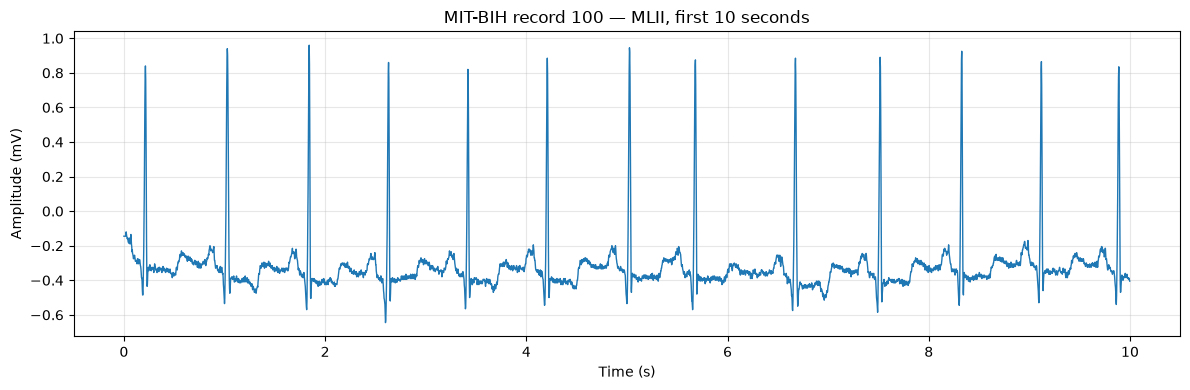

In [5]:
fs = record.fs
sample_indices = np.arange(len(ecg))
time_seconds = sample_indices / fs

print(f"Time between samples: {1000 / fs:.2f} ms")
print(f"Last sample time: {time_seconds[-1]:.4f} s")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_seconds, ecg, linewidth=1)
ax.set_title(f"MIT-BIH record {record_id} — {record.sig_name[0]}, first 10 seconds")
ax.set_xlabel("Time (s)")
ax.set_ylabel(f"Amplitude ({record.units[0]})")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Normal beat (N): 12
Atrial premature beat (A): 1


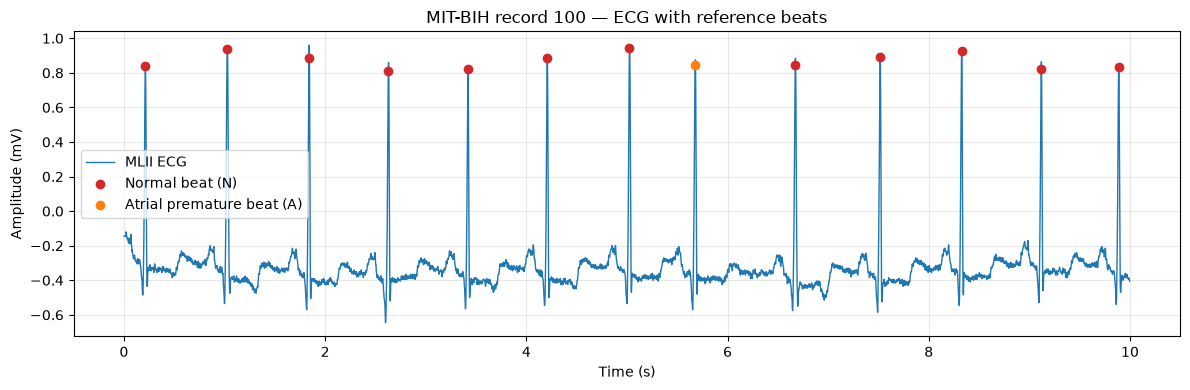

In [7]:
annotations = wfdb.rdann(record_id, "atr", pn_dir=database)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_seconds, ecg, linewidth=1, label="MLII ECG")

for symbol, label, color in [
    ("N", "Normal beat (N)", "tab:red"),
    ("A", "Atrial premature beat (A)", "tab:orange"),
]:
    beat_samples = annotations.sample[np.array(annotations.symbol) == symbol]
    beat_samples = beat_samples[beat_samples < len(ecg)]

    print(f"{label}: {len(beat_samples)}")

    if len(beat_samples) > 0:
        ax.scatter(
            time_seconds[beat_samples],
            ecg[beat_samples],
            color=color,
            label=label,
            zorder=3,
        )

ax.set_title(f"MIT-BIH record {record_id} — ECG with reference beats")
ax.set_xlabel("Time (s)")
ax.set_ylabel(f"Amplitude ({record.units[0]})")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
figure_path = figures_dir / "record_100_mlii_annotated.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()